In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, precision_recall_curve)

X_train = pd.read_csv("../data/processed/X_train_clip.csv")
X_test = pd.read_csv("../data/processed/X_test_clip.csv")
y_train = pd.read_csv("../data/processed/y_train.csv").squeeze()
y_test = pd.read_csv("../data/processed/y_test.csv").squeeze()

ratio = (y_train == 0).sum() / (y_train == 1).sum()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [2]:
# Try 12 combinations x 5 pieces = 60 small trainings (a few minutes)
param_grid = {
    "max_depth": [3, 4, 6],
    "learning_rate": [0.03, 0.1],
    "n_estimators": [200, 400],
}

xgb = GridSearchCV(
    XGBClassifier(scale_pos_weight=ratio, eval_metric="logloss", random_state=42),
    param_grid, cv=cv, scoring="roc_auc", n_jobs=-1
)
xgb.fit(X_train, y_train)

print("Best settings:", xgb.best_params_)
print("Cross-validation ROC-AUC:", round(xgb.best_score_, 3))

Best settings: {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 400}
Cross-validation ROC-AUC: 0.933


In [3]:
# Score on test with the normal 0.50 cutoff
best = xgb.best_estimator_
proba_test = best.predict_proba(X_test)[:, 1]

def show(name, proba, cutoff):
    pred = (proba >= cutoff).astype(int)
    print(f"{name} (cutoff {cutoff:.2f})")
    print("  Precision:", round(precision_score(y_test, pred, zero_division=0), 3))
    print("  Recall   :", round(recall_score(y_test, pred), 3))
    print("  F1       :", round(f1_score(y_test, pred), 3))
    print("  ROC-AUC  :", round(roc_auc_score(y_test, proba), 3))

show("Tuned XGBoost", proba_test, 0.50)

Tuned XGBoost (cutoff 0.50)
  Precision: 0.767
  Recall   : 0.465
  F1       : 0.579
  ROC-AUC  : 0.923


Best cutoff from train: 0.334


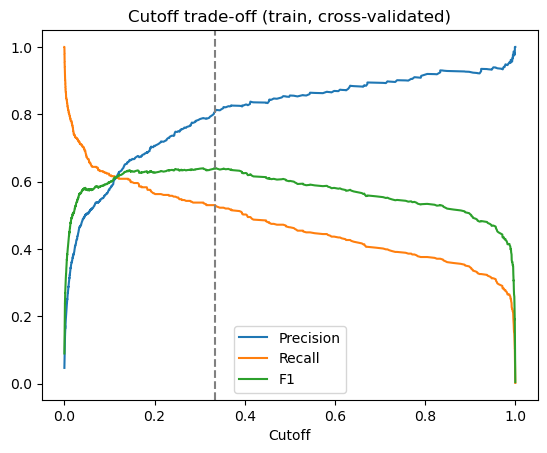

In [4]:
# Pick the best cutoff using TRAIN only (cross-validated predictions)
oof = cross_val_predict(best, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

prec, rec, thr = precision_recall_curve(y_train, oof)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
best_cutoff = thr[np.argmax(f1s)]
print("Best cutoff from train:", round(best_cutoff, 3))

plt.plot(thr, prec[:-1], label="Precision")
plt.plot(thr, rec[:-1], label="Recall")
plt.plot(thr, f1s, label="F1")
plt.axvline(best_cutoff, color="gray", linestyle="--")
plt.xlabel("Cutoff")
plt.legend()
plt.title("Cutoff trade-off (train, cross-validated)")
plt.show()

In [5]:
# Use that cutoff once on the test data
show("Tuned XGBoost", proba_test, best_cutoff)

Tuned XGBoost (cutoff 0.33)
  Precision: 0.691
  Recall   : 0.475
  F1       : 0.563
  ROC-AUC  : 0.923


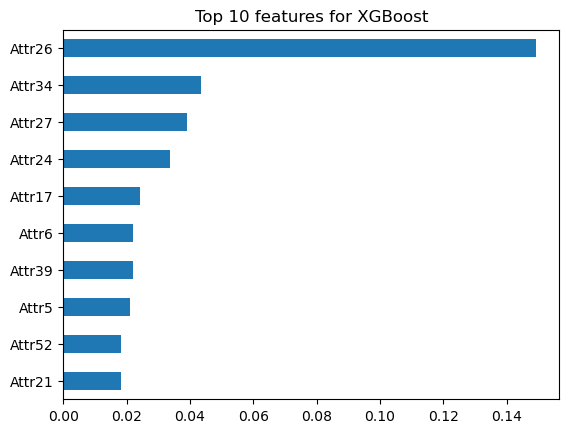

In [6]:
# Which features did XGBoost use most?
imp = pd.Series(best.feature_importances_, index=X_train.columns)
imp.sort_values(ascending=False).head(10).sort_values().plot(kind="barh")
plt.title("Top 10 features for XGBoost")
plt.show()

# 1. Which models are enough?
My recommendation: build 3 models properly. That's enough for a solid beginner-level project if you compare them fairly and explain your results.

## 1. Logistic Regression — mandatory baseline

Start here. It gives you a simple model to compare against more complex models and helps you understand how financial ratios relate to bankruptcy risk.




## 2. Random Forest — recommended

Captures nonlinear relationships and interactions between financial ratios. Compare its performance with Logistic Regression.




## 3. XGBoost — recommended final candidate

A powerful model for tabular financial data. Tune its hyperparameters using GridSearchCV and select it as your final model only if the evaluation supports that choice.